# Wine Quality Prediction Using Machine Learning

**Final Data Science Internship Project**

## 1. Project Overview
This project explores the physicochemical properties of red wine and builds a machine learning model to estimate wine quality.

### Objectives
- Load and understand the dataset.
- Clean and prepare the data.
- Perform exploratory data analysis (EDA).
- Visualize feature relationships.
- Train a Random Forest Regression model.
- Evaluate model performance using MAE, RMSE, and R².

**Dataset:** UCI Machine Learning Repository — Wine Quality (red wine).

## 2. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dataset
The notebook downloads the public red wine quality CSV from the UCI repository. An internet connection is required for this cell.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(DATA_URL, sep=";")
print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully.
Rows and columns: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 4. Understand the Dataset

In [3]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nTarget distribution:")
display(df["quality"].value_counts().sort_index())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Statistical summary:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000



Target distribution:


,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


## 5. Data Cleaning

In [4]:
print("Missing values per column:")
display(df.isnull().sum())

print("Duplicate rows before cleaning:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Cleaned dataset shape:", df.shape)

Missing values per column:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Duplicate rows before cleaning: 240
Duplicate rows after cleaning: 0
Cleaned dataset shape: (1359, 12)


## 6. Exploratory Data Analysis (EDA)

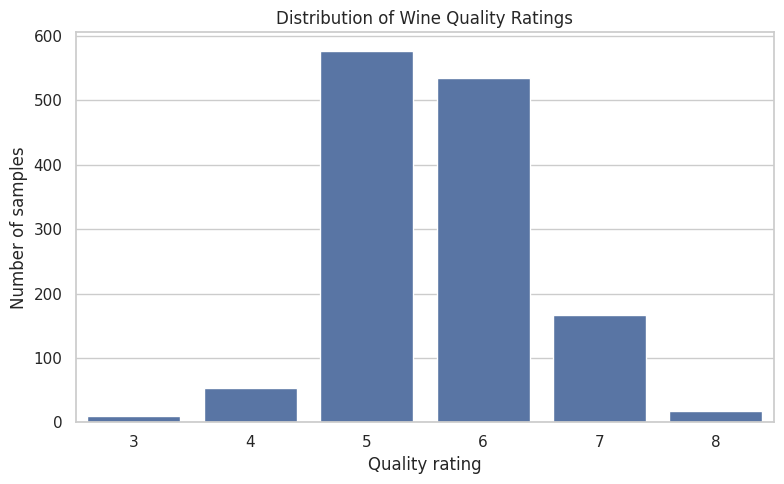

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality Ratings")
plt.xlabel("Quality rating")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

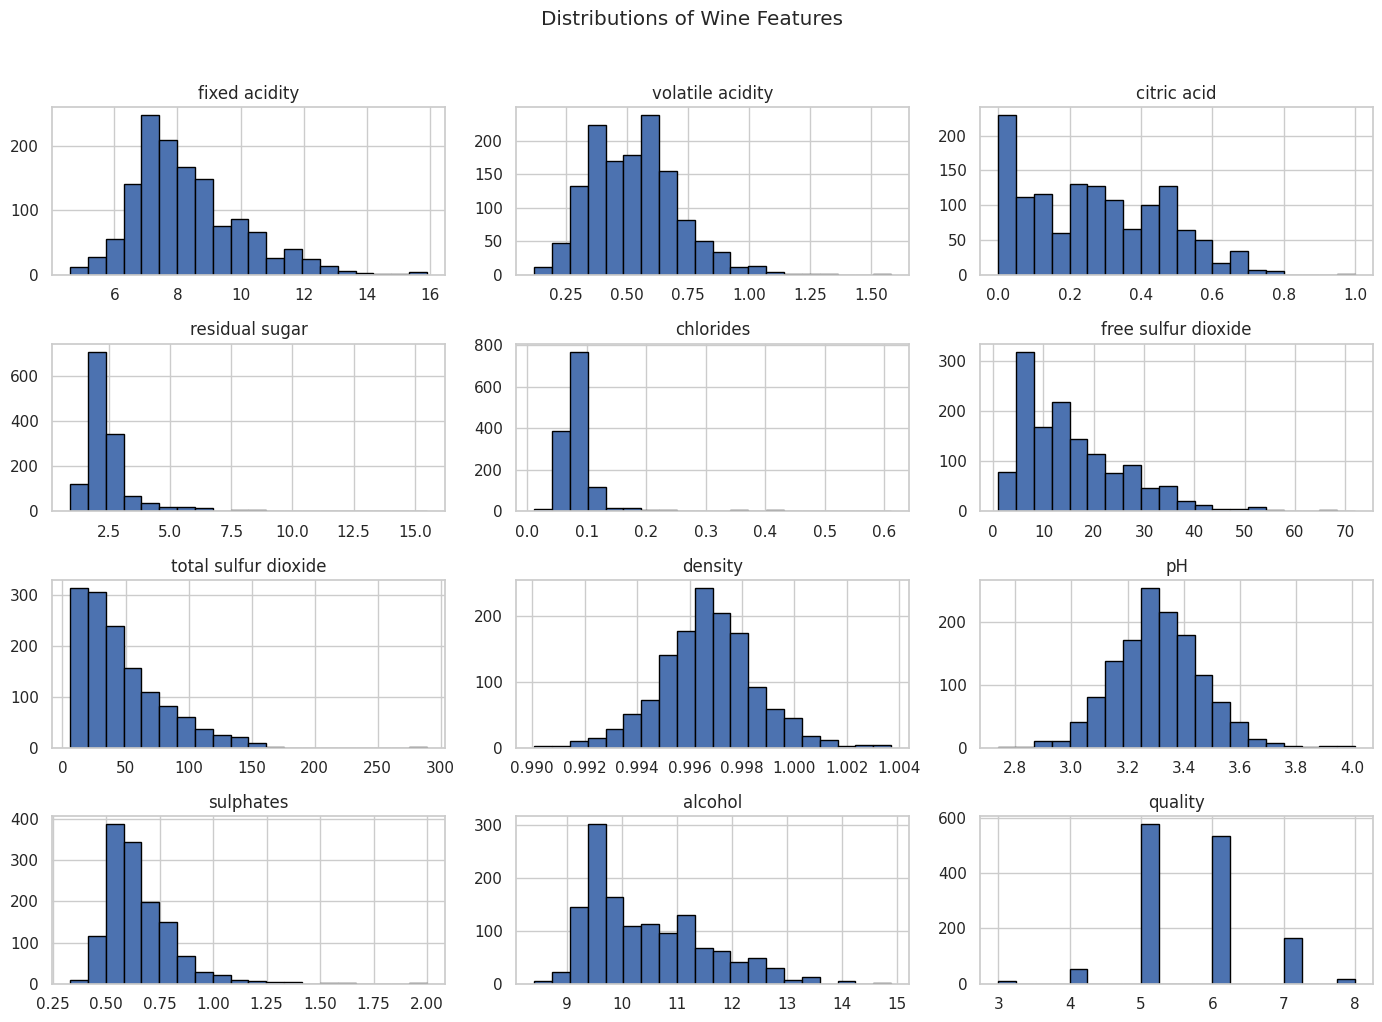

In [6]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distributions of Wine Features", y=1.02)
plt.tight_layout()
plt.show()

## 7. Correlation Analysis

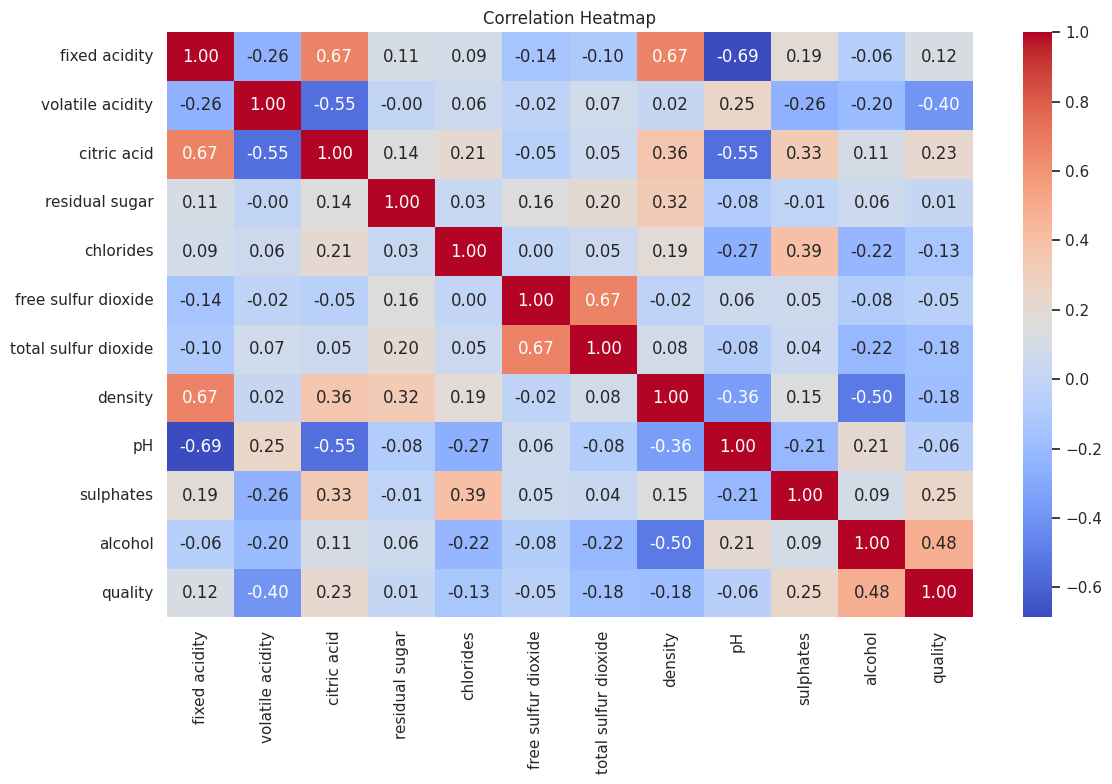

In [7]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Prepare Data for Machine Learning
The target variable is `quality`. All other columns are used as input features.

In [8]:
X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (1087, 11)
Testing feature shape: (272, 11)


## 9. Train the Machine Learning Model

In [9]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Random Forest Regressor trained successfully.")

Random Forest Regressor trained successfully.


## 10. Make Predictions

In [10]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Predicted Quality": np.round(y_pred, 2)
})

display(results.head(10))

,Actual Quality,Predicted Quality
0,5,5.01
1,6,5.98
2,7,6.36
3,5,5.55
4,4,5.36
5,7,6.80
6,5,5.61
7,5,5.12
8,6,5.86
9,5,5.54


## 11. Evaluate the Model

In [11]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R-squared (R²): {r2:.3f}")

Mean Absolute Error (MAE): 0.467
Root Mean Squared Error (RMSE): 0.617
R-squared (R²): 0.462


## 12. Actual vs Predicted Values

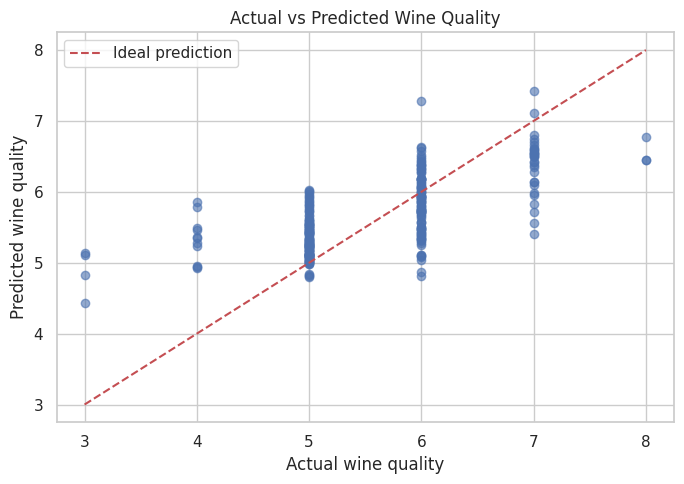

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Ideal prediction")
plt.xlabel("Actual wine quality")
plt.ylabel("Predicted wine quality")
plt.title("Actual vs Predicted Wine Quality")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Feature Importance

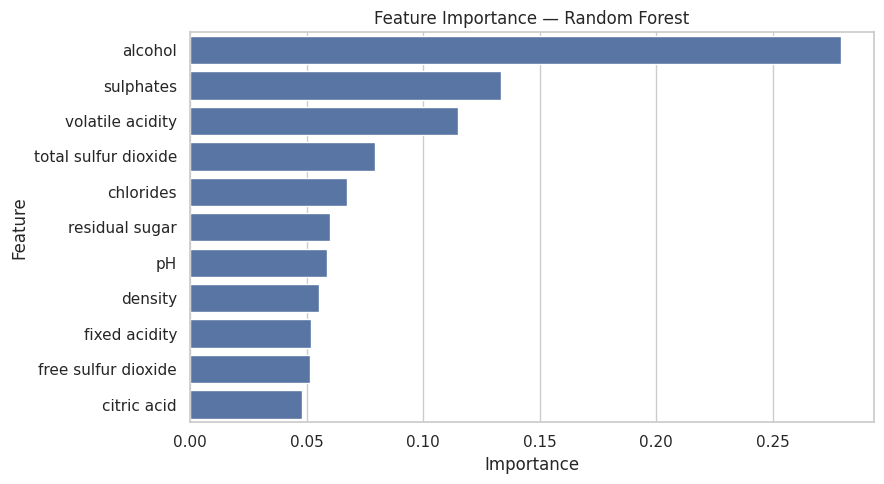

,Importance
alcohol,0.279459
sulphates,0.133570
volatile acidity,0.114824
total sulfur dioxide,0.079239
chlorides,0.067377
residual sugar,0.060217
pH,0.058817
density,0.055378
fixed acidity,0.051772
free sulfur dioxide,0.051277


In [13]:
feature_importance = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=feature_importance.values, y=feature_importance.index)
plt.title("Feature Importance — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(feature_importance.to_frame("Importance"))

## 14. Conclusion

In this project, the red wine quality dataset was explored and prepared for machine learning. Exploratory data analysis and visualizations were used to understand the data and relationships between features. A Random Forest Regressor was trained to estimate wine quality from its physicochemical properties.

The model was evaluated using MAE, RMSE, and R². The printed scores should be used when writing the final project report.

### Limitations
- The dataset contains red wine samples from a particular source and may not represent all wines.
- Wine quality is a human-rated score and can be subjective.
- The model estimates a numeric quality score; it does not guarantee real-world wine quality.

### Future Improvements
- Compare Random Forest with Linear Regression, Decision Tree, and Gradient Boosting.
- Tune hyperparameters using cross-validation.
- Test on additional datasets.

## 15. References
- UCI Machine Learning Repository: Wine Quality Data Set  
  https://archive.ics.uci.edu/dataset/186/wine+quality
- Scikit-learn documentation: https://scikit-learn.org/
- Pandas documentation: https://pandas.pydata.org/docs/